In [1]:
!pip list | grep torch

torch                                 2.14.1+cu130
torchao                               0.10.0
torchaudio                            2.11.0+cu130
torchcodec                            0.17.0+cu130
torchdata                             0.11.0
torchsummary                          1.5.1
torchtune                             0.6.1
torchvision                           0.29.1+cu130


In [2]:
%pip install tensorrt-cu13==10.14.1.48.post1
import tensorrt as trt
print(trt.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.8/879.8 kB 11.9 MB/s  0:00:00
  Created wheel for tensorrt-cu13: filename=tensorrt_cu13-10.14.1.48.post1-py2.py3-none-any.whl size=18266 sha256=3515e2c40b5365d75863a605f9cf25ef7100bb06920caf8c11e6a30b76421af1
  Stored in directory: /root/.cache/pip/wheels/2f/c3/68/f6adf1fcb4ea63ad6c1ad6630f3b5249ac738aac01fb522c17
  Created wheel for tensorrt_cu13_libs: filename=tensorrt_cu13_libs-10.14.1.48.post1-py2.py3-none-manylinux_2_28_x86_64.whl size=3437501033 sha256=f55d59e9f93ebe0967c4bc108fb4068e74cdbc50bef3e6c9936e92f21cf11352
  Stored in directory: /root/.cache/pip/wheels/c3/ed/2f/c902e1c77cb593f0f83b1a19e0813069d2b519ba26a7544db4
Succ

In [3]:
import torch

*   https://pytorch.org/blog/quantization-in-practice/
*   https://pytorch.org/docs/stable/quantization.html
*   https://pytorch.org/docs/stable/quantization-support.html

### Mapping function and Quantization Parameters

In [4]:
# r - float tensor, r' - int tensor
# S [scaling factor] = (beta - alpha) / (beta_q - alpha_q)
# Z [zero point] =  -(alpha / S - alpha_q)

def quantize(float_tensor, scale, z):
  # Q(r) = round(r/S + Z)
  return torch.round(float_tensor / scale + z)

def dequantize(int_tensor, scale, z):
  # r' = (Q(r) - Z) * S
  return (int_tensor - z) * scale

In [5]:
from torch.ao.quantization.observer import MinMaxObserver, MovingAverageMinMaxObserver, HistogramObserver

C, L = 3, 4
normal = torch.distributions.normal.Normal(0,1)
inputs = normal.sample((C, L))
print(inputs)

tensor([[ 0.6676,  1.1488, -0.1764,  1.0647],
        [-0.3590,  0.1293, -0.1559, -1.1452],
        [-0.0614, -0.8372,  2.2326, -0.6236]])


In [6]:
observers = [MinMaxObserver(), MovingAverageMinMaxObserver(), HistogramObserver()]
for obs in observers:
  obs(inputs)
  print(obs.__class__.__name__, obs.calculate_qparams())

MinMaxObserver (tensor([0.0132]), tensor([86], dtype=torch.int32))
MovingAverageMinMaxObserver (tensor([0.0132]), tensor([86], dtype=torch.int32))
HistogramObserver (tensor([0.0132]), tensor([86], dtype=torch.int32))


In [7]:
scale, z = observers[0].calculate_qparams()
reconstruction_error = torch.abs(dequantize(quantize(inputs, scale, z), scale, z) - inputs)
reconstruction_error

tensor([[0.0053, 0.0037, 0.0042, 0.0050],
        [0.0014, 0.0031, 0.0031, 0.0060],
        [0.0048, 0.0027, 0.0060, 0.0011]])

### Affine and Symmetric Quantization Schemes

In [8]:
import numpy as np
import matplotlib.pyplot as plt


def get_symmetric_range(x):
  beta = torch.max(x.max(), x.min().abs())
  return -beta.item(), beta.item()

def get_affine_range(x):
  return x.min().item(), x.max().item()

def plot(plt, data, scheme):
  boundaries = get_affine_range(data) if scheme == 'affine' else get_symmetric_range(data)
  a, _, _ = plt.hist(data, density=True, bins=100)
  ymin, ymax = np.quantile(a[a>0], [0.25, 0.95])
  plt.vlines(x=boundaries, ls='--', colors='purple', ymin=ymin, ymax=ymax)

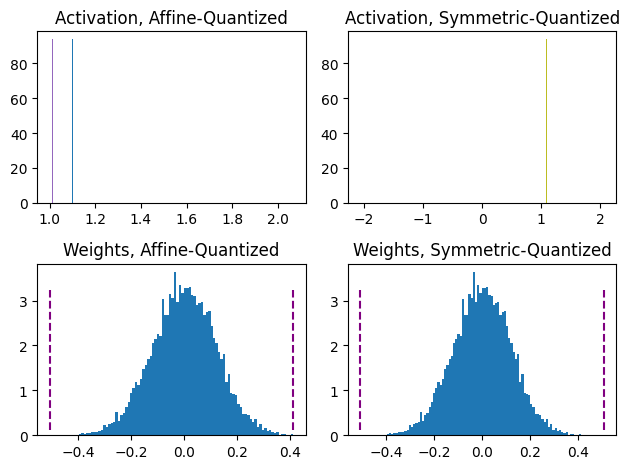

In [9]:
act =  torch.distributions.pareto.Pareto(1, 10).sample((1, 1024))
weights = torch.distributions.normal.Normal(0, 0.12).sample((3, 64, 7, 7)).flatten()

fig, axs = plt.subplots(2,2)
plot(axs[0, 0], act, 'affine')
axs[0, 0].set_title("Activation, Affine-Quantized")

plot(axs[0, 1], act, 'symmetric')
axs[0, 1].set_title("Activation, Symmetric-Quantized")

plot(axs[1, 0], weights, 'affine')
axs[1, 0].set_title("Weights, Affine-Quantized")

plot(axs[1, 1], weights, 'symmetric')
axs[1, 1].set_title("Weights, Symmetric-Quantized")

fig.tight_layout()
plt.show()

In [10]:
for qscheme in [torch.per_tensor_affine, torch.per_tensor_symmetric]:
  obs = MovingAverageMinMaxObserver(qscheme=qscheme)
  obs(inputs)
  print(f"Qscheme: {qscheme} | {obs.calculate_qparams()}")

Qscheme: torch.per_tensor_affine | (tensor([0.0132]), tensor([86], dtype=torch.int32))
Qscheme: torch.per_tensor_symmetric | (tensor([0.0175]), tensor([128]))


### Per-Tensor and Per-Channel Quantization Schemes

In [11]:
from torch.ao.quantization.observer import MovingAveragePerChannelMinMaxObserver

obs = MovingAveragePerChannelMinMaxObserver(ch_axis = 0)  # calculate qparams for all `C` channels separately
obs(inputs)
print(obs.calculate_qparams())

(tensor([0.0052, 0.0050, 0.0120]), tensor([ 34, 229,  70], dtype=torch.int32))


For weights quantization, symmetric-per-channel quantization provides better accuracies; per-tensor quantization performs poorly, possibly due to high variance in conv weights across channels from batchnorm folding.
[https://arxiv.org/abs/2004.09602]

https://github.com/pytorch/pytorch/blob/748d9d24940cd17938df963456c90fa1a13f3932/torch/ao/quantization/observer.py#L258

### Backend Engine

In [12]:
backend = 'fbgemm' #'fbgemm' if x86 else 'qnnpack' intel - oneDNN
qconfig = torch.ao.quantization.get_default_qconfig(backend)
torch.backends.quantized.engine = backend

GPUs - via TensorRT and cuDNN
https://pytorch.org/docs/stable/quantization.html#note-for-native-cpu-backends

### QConfig

In [13]:
my_qconfig = torch.ao.quantization.QConfig(
  activation=MovingAverageMinMaxObserver.with_args(qscheme=torch.per_tensor_affine),
  weight=MovingAveragePerChannelMinMaxObserver.with_args(qscheme=torch.qint8))

my_qconfig

QConfig(activation=functools.partial(<class 'torch.ao.quantization.observer.MovingAverageMinMaxObserver'>, qscheme=torch.per_tensor_affine){}, weight=functools.partial(<class 'torch.ao.quantization.observer.MovingAveragePerChannelMinMaxObserver'>, qscheme=torch.qint8){})

### Eager Mode v/s FX Graph Mode

*    Eager Mode Quantization is a beta feature. User needs to do fusion and specify where quantization and dequantization happens manually, also it only supports modules and not functionals.
*    FX Graph Mode Quantization is a new automated quantization framework in PyTorch, and currently it’s a prototype feature. It improves upon Eager Mode Quantization by adding support for functionals and automating the quantization process, although people might need to refactor the model to make the model compatible with FX Graph Mode Quantization (symbolically traceable with torch.fx)






FX Graph Mode automatically fuses eligible modules, inserts Quant/DeQuant stubs, calibrates the model and returns a quantized module - all in two method calls - but only for networks that are symbolic traceable. The examples below contain the calls using Eager Mode and FX Graph Mode for comparison.
https://pytorch.org/docs/stable/fx.html#torch.fx.symbolic_trace

In [14]:
def f(a, b):
    if b == True:
        return a
    else:
        return a * 2

In [15]:
traced_f = torch.fx.symbolic_trace(f, concrete_args={'b': False})
assert traced_f(3, False) == 6

https://pytorch.org/docs/stable/fx.html

### Post-Training Dynamic/Weight-only Quantization

Here the model’s weights are pre-quantized; the activations are quantized on-the-fly (“dynamic”) during inference. The simplest of all approaches, it has a one line API call in torch.quantization.quantize_dynamic. Currently only Linear and Recurrent (LSTM, GRU, RNN) layers are supported for dynamic quantization



*   Can result in higher accuracies since the clipping range is exactly calibrated for each input
*   Calibrating and quantizing the activations at each layer during runtime can add to the compute overhead



In [16]:
from torch import nn

# toy model
m = nn.Sequential(
  nn.Conv2d(2, 64, (8,)),
  nn.ReLU(),
  nn.Linear(16, 10),
  nn.LSTM(10, 10))

m.eval()

Sequential(
  (0): Conv2d(2, 64, kernel_size=(8,), stride=(1, 1))
  (1): ReLU()
  (2): Linear(in_features=16, out_features=10, bias=True)
  (3): LSTM(10, 10)
)

In [17]:
## EAGER MODE
from torch.ao.quantization import quantize_dynamic

model_quantized = quantize_dynamic(
    model=m, qconfig_spec={nn.LSTM, nn.Linear}, dtype=torch.qint8, inplace=False
)

/tmp/ipykernel_397/2181302342.py:4: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_quantized = quantize_dynamic(
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, 

In [18]:
## FX MODE
from torch.ao.quantization import quantize_fx

example_inputs = (torch.randn(1, 3, 224, 224),)
qconfig_dict = {"": torch.ao.quantization.default_dynamic_qconfig}  # An empty key denotes the default applied to all modules
model_prepared = quantize_fx.prepare_fx(m, qconfig_dict, example_inputs)
model_quantized = quantize_fx.convert_fx(model_prepared)

/tmp/ipykernel_397/15622409.py:6: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_prepared = quantize_fx.prepare_fx(m, qconfig_dict, example_inputs)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/quantize_fx.py:146: FutureWarning: Passing a QConfig dictionary to prepare is deprecated and will not be supported in a future version. Please pass in a QConf

In [19]:
torch.ao.quantization.default_dynamic_qconfig

QConfig(activation=functools.partial(<class 'torch.ao.quantization.observer.PlaceholderObserver'>, dtype=torch.quint8, quant_min=0, quant_max=255, is_dynamic=True){}, weight=functools.partial(<class 'torch.ao.quantization.observer.MinMaxObserver'>, dtype=torch.qint8, qscheme=torch.per_tensor_symmetric){})

### Post-Training Static Quantization (PTQ)

PTQ also pre-quantizes model weights but instead of calibrating activations on-the-fly, the clipping range is pre-calibrated and fixed (“static”) using validation data. Activations stay in quantized precision between operations during inference. About 100 mini-batches of representative data are sufficient to calibrate the observers

*   Static quantization has faster inference than dynamic quantization because it eliminates the float<->int conversion costs between layers
*   Static quantized models may need regular re-calibration to stay robust against distribution-drift



In [20]:
# Static quantization of a model consists of the following steps:

#     Fuse modules
#     Insert Quant/DeQuant Stubs
#     Prepare the fused module (insert observers before and after layers)
#     Calibrate the prepared module (pass it representative data)
#     Convert the calibrated module (replace with quantized version)

import torch
from torch import nn
import copy

backend = "fbgemm"  # running on a x86 CPU. Use "qnnpack" if running on ARM.

model = nn.Sequential(
     nn.Conv2d(2, 64, 3),
     nn.ReLU(),
     nn.Conv2d(64, 128, 3),
     nn.ReLU()
)

In [21]:
## EAGER MODE
m = copy.deepcopy(model)
m.eval()

"""Fuse
- Inplace fusion replaces the first module in the sequence with the fused module, and the rest with identity modules
"""
torch.ao.quantization.fuse_modules(m, ['0','1'], inplace=True) # fuse first Conv-ReLU pair
torch.ao.quantization.fuse_modules(m, ['2','3'], inplace=True) # fuse second Conv-ReLU pair

"""Insert stubs"""
m = nn.Sequential(torch.ao.quantization.QuantStub(),
                  *m,
                  torch.ao.quantization.DeQuantStub())

"""Prepare"""
m.qconfig = torch.ao.quantization.get_default_qconfig(backend)
torch.ao.quantization.prepare(m, inplace=True)

"""Calibrate
- This example uses random data for convenience. Use representative (validation) data instead.
"""
with torch.inference_mode():
  for _ in range(10):
    x = torch.rand(1, 2, 28, 28)
    m(x)

"""Convert"""
torch.ao.quantization.convert(m, inplace=True)

"""Check"""
print(m[1].weight().element_size()) # 1 byte instead of 4 bytes for FP32

1


/tmp/ipykernel_397/213743822.py:18: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.ao.quantization.prepare(m, inplace=True)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTor

In [22]:
m[1].weight()

tensor([[[[ 0.1563,  0.1931,  0.1140],
          [-0.1214, -0.2059, -0.1306],
          [-0.0423,  0.0515,  0.1839]],

         [[ 0.1048, -0.1765, -0.0074],
          [-0.0754,  0.1655,  0.1545],
          [-0.1802, -0.0735, -0.2354]]],


        [[[-0.1309,  0.0524,  0.0727],
          [ 0.1571,  0.0145, -0.1178],
          [ 0.0669, -0.0436, -0.0538]],

         [[ 0.0989, -0.1861, -0.0727],
          [-0.1018,  0.1454,  0.0800],
          [-0.1745,  0.1556, -0.0393]]],


        [[[ 0.0787,  0.2325,  0.2032],
          [-0.0275,  0.1794, -0.1941],
          [ 0.0055,  0.0293,  0.1062]],

         [[ 0.2087,  0.0842, -0.0183],
          [-0.1135,  0.1080,  0.1922],
          [ 0.2179, -0.1776,  0.0714]]],


        ...,


        [[[-0.0309,  0.0272,  0.1234],
          [-0.1924,  0.1597, -0.1343],
          [-0.1634, -0.1180, -0.1016]],

         [[-0.0653, -0.0653,  0.1035],
          [ 0.1851, -0.0545,  0.0908],
          [ 0.0690, -0.1742, -0.2323]]],


        [[[ 0.0730,  0.23

In [23]:
## FX GRAPH
from torch.ao.quantization import quantize_fx

m = copy.deepcopy(model)
m.eval()
qconfig_dict = {"": torch.ao.quantization.get_default_qconfig(backend)}

# Prepare
example_inputs = (torch.randn(1, 3, 224, 224),)
model_prepared = quantize_fx.prepare_fx(m, qconfig_dict, example_inputs)

# Calibrate - Use representative (validation) data.
with torch.inference_mode():
  for _ in range(10):
    x = torch.rand(1, 2, 28, 28)
    model_prepared(x)

# quantize
model_quantized = quantize_fx.convert_fx(model_prepared)

/tmp/ipykernel_397/750729956.py:10: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_prepared = quantize_fx.prepare_fx(m, qconfig_dict, example_inputs)
/tmp/ipykernel_397/750729956.py:19: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.q

### SENSITIVITY ANALYSIS

In [24]:
# ONE-AT-A-TIME SENSITIVITY ANALYSIS

for quantized_layer, _ in model.named_modules():
  print("Only quantizing layer: ", quantized_layer)

  # The module_name key allows module-specific qconfigs.
  qconfig_dict = {"": None,
  "module_name":[(quantized_layer, torch.quantization.get_default_qconfig(backend))]}

  example_inputs = (torch.randn(1, 3, 224, 224),)
  model_prepared = quantize_fx.prepare_fx(model, qconfig_dict, example_inputs)
  # calibrate
  model_quantized = quantize_fx.convert_fx(model_prepared)
  # evaluate(model)

Only quantizing layer:  
Only quantizing layer:  0
Only quantizing layer:  1
Only quantizing layer:  2
Only quantizing layer:  3


/tmp/ipykernel_397/1147990886.py:11: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_prepared = quantize_fx.prepare_fx(model, qconfig_dict, example_inputs)
/tmp/ipykernel_397/1147990886.py:13: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torc

 Numeric Suite - https://pytorch.org/tutorials/prototype/numeric_suite_tutorial.html

In [25]:
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets
import torchvision.transforms as transforms
import os
import torch.ao.quantization
import torch.ao.ns._numeric_suite as ns
from torch.ao.quantization import (
    default_eval_fn,
    default_qconfig,
    quantize,
)

In [26]:
float_model = torchvision.models.quantization.resnet18(pretrained=True, quantize=False)
float_model.to('cpu')
float_model.eval()
float_model.fuse_model()
float_model.qconfig = torch.quantization.default_qconfig
img_data = (torch.rand(2, 3, 10, 10, dtype=torch.float), torch.randint(0, 1, (2,), dtype=torch.long))
qmodel = quantize(float_model, default_eval_fn, [[img_data]], inplace=False)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 182MB/s]
/tmp/ipykernel_397/409614095.py:7: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  qmodel = quantize(float_model, default_eval_fn, [[img_data]], inplace=False)


In [27]:
def compute_error(x, y):
    Ps = torch.norm(x)
    Pn = torch.norm(x - y)
    return 20 * torch.log10(Ps/Pn)

wt_compare_dict = ns.compare_weights(float_model.state_dict(), qmodel.state_dict())
for key in wt_compare_dict:
    print(key, compute_error(wt_compare_dict[key]['float'], wt_compare_dict[key]['quantized'].dequantize()))

print("---")

act_compare_dict = ns.compare_model_outputs(float_model, qmodel, img_data[0])
for key in act_compare_dict:
    print(key, compute_error(act_compare_dict[key]['float'][0], act_compare_dict[key]['quantized'][0].dequantize()))


conv1.weight tensor(31.6638)
layer1.0.conv1.weight tensor(30.6450)
layer1.0.conv2.weight tensor(31.1528)
layer1.1.conv1.weight tensor(32.1438)
layer1.1.conv2.weight tensor(31.2477)
layer2.0.conv1.weight tensor(30.9890)
layer2.0.conv2.weight tensor(28.8233)
layer2.0.downsample.0.weight tensor(31.5558)
layer2.1.conv1.weight tensor(30.7668)
layer2.1.conv2.weight tensor(28.4516)
layer3.0.conv1.weight tensor(30.9247)
layer3.0.conv2.weight tensor(26.6841)
layer3.0.downsample.0.weight tensor(28.7825)
layer3.1.conv1.weight tensor(28.9707)
layer3.1.conv2.weight tensor(25.6784)
layer4.0.conv1.weight tensor(26.8495)
layer4.0.conv2.weight tensor(25.8394)
layer4.0.downsample.0.weight tensor(28.6355)
layer4.1.conv1.weight tensor(26.8758)
layer4.1.conv2.weight tensor(28.4319)
fc._packed_params._packed_params tensor(32.6505)
---
conv1.stats tensor(37.3891, grad_fn=<MulBackward0>)
layer1.0.conv1.stats tensor(30.0025, grad_fn=<MulBackward0>)
layer1.0.conv2.stats tensor(28.4014, grad_fn=<MulBackward0>)
l

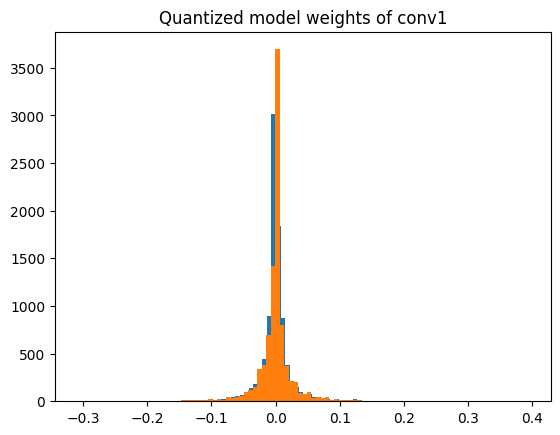

In [28]:
import matplotlib.pyplot as plt

f = wt_compare_dict['conv1.weight']['float'].flatten()
plt.hist(f, bins = 100)

q = wt_compare_dict['conv1.weight']['quantized'].flatten().dequantize()
plt.hist(q, bins = 100)
plt.title("Quantized model weights of conv1")
plt.show()

### RECOMMENDATIONS FOR YOUR WORKFLOW

![](https://drive.google.com/uc?export=view&id=1ij7GElwiKFNmJ221aKpkDRwMj5i-2DLh)



*   Large (10M+ parameters) models are more robust to quantization error
*   Quantizing a model from a FP32 checkpoint provides better accuracy than training an INT8 model from scratch
*   Dynamic Quantization is an easy first step, especially if your model has many Linear or Recurrent layers
*   Use symmetric-per-channel quantization with MinMax observers for quantizing weights. Use affine-per-tensor quantization with MovingAverageMinMax observers for quantizing activations
*   Use metrics like SQNR to identify which layers are most suscpetible to quantization error. Turn off quantization on these layers

Eager mode https://pytorch.org/docs/stable/quantization.html#eager-mode-quantization



*   https://pytorch.org/docs/stable/quantization.html#post-training-dynamic-quantization
*   https://pytorch.org/docs/stable/quantization.html#post-training-static-quantization


FX Graph https://pytorch.org/docs/stable/quantization.html#prototype-fx-graph-mode-quantization



*   https://pytorch.org/tutorials/prototype/fx_graph_mode_ptq_static.html
*   https://pytorch.org/tutorials/prototype/fx_graph_mode_ptq_dynamic.html





## New forkflow with torchao



In [29]:
!pip install torchao

In [30]:
import copy
import torch

class ToyLinearModel(torch.nn.Module):
    def __init__(self, m: int, n: int, k: int):
        super().__init__()
        self.linear1 = torch.nn.Linear(m, n, bias=False)
        self.linear2 = torch.nn.Linear(n, k, bias=False)

    def forward(self, x):
        x = self.linear1(x)
        x = self.linear2(x)
        return x

model = ToyLinearModel(1024, 1024, 1024).eval()

# Optional: compile model for faster inference and generation
model = torch.compile(model, mode="max-autotune", fullgraph=True)
model_f32 = copy.deepcopy(model)


In [31]:
from torchao.quantization import Int4DynamicActivationInt4WeightConfig, quantize_
quantize_(model, Int4DynamicActivationInt4WeightConfig())

In [32]:
from torchao.utils import (
    benchmark_model,
    unwrap_tensor_subclass,
)

num_runs = 100
torch._dynamo.reset()
example_inputs = (torch.randn(1, 1024, dtype=torch.float32),)
f32_time = benchmark_model(model_f32, num_runs, example_inputs)
int4_time = benchmark_model(model, num_runs, example_inputs)

print("f32 mean time: %0.3f ms" % f32_time)
print("int4 mean time: %0.3f ms" % int4_time)
print("speedup: %0.1fx" % (f32_time / int4_time))

/usr/local/lib/python3.13/dist-packages/torch/_functorch/_aot_autograd/autograd_cache.py:707: UserWarning: LinearActivationQuantizedTensor does not implement _stable_hash_for_caching. For PT2-compatible tensor subclasses, it is recommended to implement _stable_hash_for_caching(self) -> str for stable AOT autograd caching.
  warn_once(


f32 mean time: 0.231 ms
int4 mean time: 0.106 ms
speedup: 2.2x


In [33]:
import os
torch.save(model, "/tmp/int4_model.pt")
torch.save(model_f32, "/tmp/f32_model.pt")
int4_model_size_mb = os.path.getsize("/tmp/int4_model.pt") / 1024 / 1024
f32_model_size_mb = os.path.getsize("/tmp/f32_model.pt") / 1024 / 1024

print("int4 model size: %.2f MB" % int4_model_size_mb)

print("f32 model size: %.2f MB" % f32_model_size_mb)


int4 model size: 1.01 MB
f32 model size: 8.00 MB


### Neural Network Compression Framework (NNCF)

In [34]:
!git clone https://github.com/openvinotoolkit/nncf

Cloning into 'nncf'...
remote: Enumerating objects: 103813, done.
remote: Counting objects: 100% (922/922), done.
remote: Compressing objects: 100% (525/525), done.
remote: Total 103813 (delta 685), reused 397 (delta 397), pack-reused 102891 (from 3)
Receiving objects: 100% (103813/103813), 73.12 MiB | 12.95 MiB/s, done.
Resolving deltas: 100% (70069/70069), done.


In [35]:
# %%capture
%cd nncf
!pip install .[torch]
%cd /content

/content/nncf
Processing ./.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 14.7 MB/s  0:00:00
  Created wheel for nncf: filename=nncf-3.6.0.dev0+0d605e5da-py3-none-any.whl size=803937 sha256=6296f94afb99873bebff7b7ac40c16c58841379557fcb2e98354e4270b104587
  Stored in directory: /tmp/pip-ephem-wheel-cache-rq2vy_6v/wheels/6d/e0/88/fc57195154b6b185a52dc73cff95dc1de3abc6b98b88029e3e
Successfully built nncf
  Attempting uninstall: networkx
    Found existing installation: networkx 3.7
    Uninstalling networkx-3.7:
      Successfully uninstalled networkx-3.7
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [nncf]
/content


In [36]:
import torch
import nncf.torch  # Important - must be imported before any other external package that depends on torch

https://github.com/openvinotoolkit/nncf/tree/develop
https://github.com/openvinotoolkit/nncf/blob/develop/docs/compression_algorithms/Quantization.md
https://github.com/openvinotoolkit/nncf/blob/develop/examples/torch/classification/configs/quantization/inception_v3_imagenet_int8.json

https://dev-discuss.pytorch.org/t/torch-ao-quantization-migration-plan/2810
https://docs.pytorch.org/ao/stable

---

# ONNX and TensorRT

## 1. Overview

**ONNX (Open Neural Network Exchange)** is an interoperable format for representing neural network graphs, weights and input/output information. A PyTorch model can be exported to an `.onnx` file and deployed in different inference frameworks.

**ONNX Runtime** executes ONNX models using CPU, CUDA and other execution providers. It also provides post-training quantization tools.

**NVIDIA TensorRT** is a compiler and runtime for inference on NVIDIA GPUs. It parses compatible ONNX graphs, optimizes layers and selects efficient kernels, and produces serialized inference engines (`.engine`). TensorRT engines depend on the hardware and software environment used to build them.

A typical deployment path is:

```text
PyTorch model → ONNX FP32 → ONNX Runtime (CPU/GPU)
                           ├── ONNX Runtime dynamic INT8
                           ├── ONNX Runtime static INT8 (Q/DQ)
                           └── TensorRT FP16 or calibrated INT8
```

**FP16** is a floating-point precision mode. **INT8 quantization** maps values to integers using scaling parameters. Static INT8 quantization requires representative calibration data.

## 2. Exporting a PyTorch model to ONNX

First, train a compact fully connected network on the `sklearn` handwritten-digits dataset. The model will be used throughout the ONNX and TensorRT sections.

In [37]:
%pip -q install onnx onnxruntime onnxscript scikit-learn

In [38]:
import numpy as np
import torch
from torch import nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

np.random.seed(42)
torch.manual_seed(42)

images, labels = load_digits(return_X_y=True)
images = (images / 16.0).astype(np.float32)
train_x, test_x, train_y, test_y = train_test_split(
    images, labels, test_size=0.2, random_state=42, stratify=labels
)

export_model = nn.Sequential(
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
)
optimizer = torch.optim.Adam(export_model.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()

x_train_tensor = torch.from_numpy(train_x)
y_train_tensor = torch.from_numpy(train_y).long()
for epoch in range(30):
    optimizer.zero_grad()
    loss = loss_fn(export_model(x_train_tensor), y_train_tensor)
    loss.backward()
    optimizer.step()

export_model.eval()
with torch.no_grad():
    predictions = export_model(torch.from_numpy(test_x)).argmax(dim=1).numpy()
print(f"PyTorch accuracy: {(predictions == test_y).mean():.2%}")

PyTorch accuracy: 94.44%


In [39]:
from pathlib import Path
import onnx
import onnxruntime as ort

onnx_fp32_path = "digits_fp32.onnx"
dummy_input = torch.from_numpy(test_x[:1].copy())

torch.onnx.export(
    export_model,
    (dummy_input,),
    onnx_fp32_path,
    input_names=["input"],
    output_names=["logits"],
    opset_version=18,
    dynamo=True,
)

onnx.checker.check_model(onnx.load(onnx_fp32_path))
fp32_session = ort.InferenceSession(onnx_fp32_path, providers=["CPUExecutionProvider"])
with torch.no_grad():
    pytorch_logits = export_model(dummy_input).numpy()
onnx_logits = fp32_session.run(None, {"input": dummy_input.numpy()})[0]

print("ONNX export validated")
print("Maximum output difference:", np.max(np.abs(pytorch_logits - onnx_logits)))
print("ONNX file size:", Path(onnx_fp32_path).stat().st_size, "bytes")

[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX export validated
Maximum output difference: 1.1920929e-06
ONNX file size: 4614 bytes


## 3. Quantization with ONNX Runtime

**Dynamic quantization** stores quantized weights and computes activation quantization parameters during inference. It is commonly used for networks with linear layers.

**Static quantization** uses a calibration dataset to determine activation ranges before inference. In a **Q/DQ ONNX graph**, `QuantizeLinear` and `DequantizeLinear` nodes explicitly express the quantization scales and locations; compatible graphs can also be imported into TensorRT.

In [40]:
from onnxruntime.quantization import quantize_dynamic, QuantType

onnx_dynamic_int8_path = "digits_dynamic_int8.onnx"
quantize_dynamic(
    model_input=onnx_fp32_path,
    model_output=onnx_dynamic_int8_path,
    weight_type=QuantType.QInt8,
)

dynamic_session = ort.InferenceSession(
    onnx_dynamic_int8_path, providers=["CPUExecutionProvider"]
)
dynamic_logits = dynamic_session.run(None, {"input": dummy_input.numpy()})[0]
print("Max difference after dynamic INT8:", np.max(np.abs(onnx_logits - dynamic_logits)))

for p in [onnx_fp32_path, onnx_dynamic_int8_path]:
    print(f"{p}: {Path(p).stat().st_size / 1024:.1f} KiB")

Max difference after dynamic INT8: 0.39864016
digits_fp32.onnx: 4.5 KiB
digits_dynamic_int8.onnx: 9.0 KiB


### Static INT8 quantization

For calibration, use representative **training** inputs (not test-set inputs). The quantizer estimates the activation ranges and inserts Q/DQ operations into the exported graph. Quantized ONNX operator support varies by execution provider and TensorRT version.

In [41]:
from onnxruntime.quantization import (
    CalibrationDataReader, QuantFormat, QuantType, quantize_static
)

class DigitsCalibrationReader(CalibrationDataReader):
    def __init__(self, samples, count=128):
        self.iterator = iter(
            {"input": row[None, :].astype(np.float32)}
            for row in samples[:count]
        )

    def get_next(self):
        return next(self.iterator, None)

onnx_qdq_path = "digits_static_qdq_int8.onnx"
quantize_static(
    model_input=onnx_fp32_path,
    model_output=onnx_qdq_path,
    calibration_data_reader=DigitsCalibrationReader(train_x),
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QInt8,
    weight_type=QuantType.QInt8,
    per_channel=True,
    op_types_to_quantize=["MatMul", "Gemm"],
    extra_options={"ActivationSymmetric": True, "WeightSymmetric": True},
)

onnx.checker.check_model(onnx.load(onnx_qdq_path))
static_session = ort.InferenceSession(onnx_qdq_path, providers=["CPUExecutionProvider"])
static_logits = static_session.run(None, {"input": dummy_input.numpy()})[0]
print("Max difference after static INT8:", np.max(np.abs(onnx_logits - static_logits)))
print(f"Static INT8 ONNX size: {Path(onnx_qdq_path).stat().st_size / 1024:.1f} KiB")

Max difference after static INT8: 2.7310138
Static INT8 ONNX size: 12.1 KiB


In [42]:
def onnx_accuracy(session, features, targets):
    correct = 0
    for sample, target in zip(features, targets):
        logits = session.run(None, {"input": sample[None, :].astype(np.float32)})[0]
        correct += int(np.argmax(logits[0]) == target)
    return correct / len(targets)

for name, runtime in [
    ("FP32", fp32_session),
    ("Dynamic INT8", dynamic_session),
    ("Static INT8 Q/DQ", static_session),
]:
    print(f"{name:16s} accuracy: {onnx_accuracy(runtime, test_x, test_y):.2%}")

FP32             accuracy: 94.44%
Dynamic INT8     accuracy: 94.17%
Static INT8 Q/DQ accuracy: 89.72%


## 4. TensorRT export and inference

TensorRT is intended for NVIDIA GPUs and requires compatible CUDA drivers and TensorRT tools. The `trtexec` utility is distributed with full TensorRT installations or NVIDIA TensorRT containers; it is not normally present in standard Google Colab runtimes.

On a machine with `trtexec` installed, convert the ONNX model into a TensorRT engine:

```bash
# Enable FP16 tactics
trtexec --onnx=digits_fp32.onnx --saveEngine=digits_fp16.engine --fp16

# Use the explicitly quantized ONNX graph for INT8
trtexec --onnx=digits_static_qdq_int8.onnx --saveEngine=digits_int8.engine

# Run a benchmark with an existing engine
trtexec --loadEngine=digits_fp16.engine
```

`--fp16` permits TensorRT to use FP16 kernels where advantageous; it does not force every operation into FP16. For INT8, a compatible Q/DQ graph specifies the quantization scales. An arbitrary FP32 model does **not** become properly calibrated simply by adding `--int8`.

TensorRT may reject unsupported operators or quantization patterns, so always inspect parser/build logs.

In [43]:
import shutil
import subprocess

trtexec = shutil.which("trtexec")
if not torch.cuda.is_available():
    print("TensorRT build skipped: an NVIDIA CUDA GPU is required.")
elif trtexec is None:
    print("TensorRT build skipped: trtexec is not installed.")
else:
    subprocess.run([
        trtexec,
        f"--onnx={onnx_fp32_path}",
        "--saveEngine=digits_fp16.engine",
        "--fp16",
    ], check=True)

TensorRT build skipped: trtexec is not installed.


**References:** [PyTorch ONNX exporter](https://docs.pytorch.org/docs/stable/onnx) · [ONNX Runtime quantization](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html) · [TensorRT ONNX deployment](https://docs.nvidia.com/deeplearning/tensorrt/latest/getting-started/quick-start-onnx-deployment.html) · [TensorRT quantization](https://docs.nvidia.com/deeplearning/tensorrt/latest/inference-library/work-with-quantized-types.html).

**Домашнее задание**: реализовать Post Training Quantization для предобученной float32 torch модели на выбранном наборе данных. Квантизация обязательно должна проводиться с использованием калибровочной подвыборки. К результатам прилагаются мини результаты исследования влияния гиперпараметров квантизации (см. начало ноутбка). Необходимо показать разные варианты с учетом и без SENSITIVITY анализа. Разрешается использовать дополнительные фреймворки после обсуждения. Добавить сравнение с экспортированной ONNX и TensorRT весами. Важно наличие таблиц скорость / качество / размер.

## Решение ДЗ · статическая квантизация ResNet‑18



In [44]:
import platform
import random
from copy import deepcopy
from itertools import islice
from pathlib import Path
from statistics import median
from time import perf_counter_ns

import torch
import torchvision
from IPython.display import HTML, display
from html import escape
from torch.ao.quantization import (
    HistogramObserver, MinMaxObserver, PerChannelMinMaxObserver, QConfig, QConfigMapping,
)
from torch.ao.quantization.quantize_fx import prepare_fx, convert_fx
from torch.utils.data import DataLoader
from torchvision import datasets, models

SEED = 42
N_THREADS = 2
torch.set_num_threads(N_THREADS)
backend = next((b for b in ("x86", "fbgemm", "qnnpack")
                if b in torch.backends.quantized.supported_engines), None)
if backend is None:
    raise RuntimeError("Нужна CPU-сборка PyTorch с x86, fbgemm или qnnpack.")
torch.backends.quantized.engine = backend
artifacts = Path("ptq_artifacts")
artifacts.mkdir(exist_ok=True)
print(f"{platform.machine()}, PyTorch {torch.__version__}, torchvision {torchvision.__version__}, "
      f"INT8 backend {backend}, потоков CPU: {N_THREADS}")

x86_64, PyTorch 2.14.1+cu130, torchvision 0.29.1+cu130, INT8 backend x86, потоков CPU: 2


### Модель и выборки

Используем опубликованные FP32-веса ResNet‑18 и их стандартную обработку изображений. Для калибровки берём 80 изображений из train, для выбора блока — ещё 30. На 150 изображениях из val считаем top-1 по всем 1000 выходам ImageNet. Каждая выборка сбалансирована по десяти классам Imagenette.

In [45]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
fp32 = models.resnet18(weights=weights).cpu().float().eval()
data_root = Path("ptq_data")
image_root = data_root / "imagenette2-160"
datasets.Imagenette(data_root, size="160px", download=not image_root.is_dir())
train = datasets.ImageFolder(image_root / "train", transform=weights.transforms())
val = datasets.ImageFolder(image_root / "val", transform=weights.transforms())

# Имена ниже совпадают с именами классов в метаданных весов ImageNet-1K.
class_names = {
    "n01440764": "tench", "n02102040": "English springer", "n02979186": "cassette player",
    "n03000684": "chain saw", "n03028079": "church", "n03394916": "French horn",
    "n03417042": "garbage truck", "n03425413": "gas pump", "n03445777": "golf ball",
    "n03888257": "parachute",
}
assert train.classes == val.classes and set(train.classes) == set(class_names)
imagenet_labels = [weights.meta["categories"].index(class_names[wnid]) for wnid in train.classes]


def balanced_indices(dataset, per_class):
    rng = random.Random(SEED)
    groups = [rng.sample([i for i, y in enumerate(dataset.targets) if y == label], per_class)
              for label in range(len(dataset.classes))]
    # Первые 20 элементов содержат по два изображения каждого класса.
    return [index for group_round in zip(*groups) for index in group_round]


def materialize(dataset, indices):
    samples = []
    for index in indices:
        image, label = dataset[index]
        samples.append((image.unsqueeze(0), imagenet_labels[label]))
    return samples


train_ids = balanced_indices(train, 11)
cal_ids, probe_ids = train_ids[:80], train_ids[80:]
assert set(cal_ids).isdisjoint(probe_ids)
cal_samples = materialize(train, cal_ids)
probe_samples = materialize(train, probe_ids)
test_samples = materialize(val, balanced_indices(val, 15))
# Каждый элемент уже содержит батч из одного изображения.
cal_loader = DataLoader(cal_samples, batch_size=None, shuffle=False)
print(f"Калибровка: {len(cal_samples)}, выбор блока: {len(probe_samples)}, тест: {len(test_samples)}")

100%|██████████| 99.0M/99.0M [00:02<00:00, 36.9MB/s]


Калибровка: 80, выбор блока: 30, тест: 150


### Как измеряем качество, задержку и размер

Для каждой модели используем одинаковые изображения и batch size 1. Задержка — медиана 30 вызовов после прогрева, от готового тензора на CPU до логитов на CPU. Для TensorRT это включает копирование на GPU и обратно. Размер в МиБ измеряем по сохранённому файлу: веса и параметры квантизации PyTorch, граф с весами ONNX или сериализованный движок TensorRT.

In [46]:
rows = []


def table(records):
    columns = list(dict.fromkeys(k for row in records for k in row))
    header = "".join(f"<th>{escape(key)}</th>" for key in columns)
    body = []
    for row in records:
        values = [row.get(key, "—") for key in columns]
        cells = [f"{v:.3f}" if isinstance(v, float) else str(v) for v in values]
        body.append("<tr>" + "".join(f"<td>{escape(v)}</td>" for v in cells) + "</tr>")
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{''.join(body)}</tbody></table>"))


@torch.inference_mode()
def record(name, device, path, predict, synchronize=lambda: None):
    # Top-1 среди всех 1000 классов. Таймер получает уже подготовленный вход на CPU.
    correct = sum(predict(x).argmax(1).item() == y for x, y in test_samples)
    for x, _ in test_samples[:5]:
        predict(x)
    synchronize()
    timings = []
    for _ in range(3):
        for x, _ in test_samples[:10]:
            start = perf_counter_ns()
            predict(x)
            synchronize()
            timings.append((perf_counter_ns() - start) / 1e6)
    rows[:] = [r for r in rows if r["Модель"] != name]
    rows.append({"Модель": name, "Устройство": device, "Top-1, %": 100 * correct / len(test_samples),
                 "Медиана, мс": median(timings), "Размер, МиБ": path.stat().st_size / 2**20})


def record_torch(name, filename, model):
    path = artifacts / filename
    torch.save(model.state_dict(), path)
    record(name, "CPU", path, model)


record_torch("PyTorch FP32", "resnet18_fp32.pt", fp32)
table(rows)

Модель,Устройство,"Top-1, %","Медиана, мс","Размер, МиБ"
PyTorch FP32,CPU,68.000,52.886,44.667


### Гиперпараметры квантизации

В базовом варианте калибруем диапазон активаций MinMax на 80 изображениях и используем отдельный масштаб для каждого выходного канала весов. Затем меняем по одному условию: размер калибровочной выборки, способ оценки диапазона активаций или схему квантизации весов.

In [47]:
def static_ptq(n_cal, activation=MinMaxObserver, per_channel=True, keep_float=None):
    weight_observer = (PerChannelMinMaxObserver.with_args(dtype=torch.qint8,
                       qscheme=torch.per_channel_symmetric, ch_axis=0) if per_channel else
                       MinMaxObserver.with_args(dtype=torch.qint8, qscheme=torch.per_tensor_symmetric))
    # U8 активации, S8 веса. На x86 используем диапазон активаций 0..127.
    act_observer = activation.with_args(dtype=torch.quint8, qscheme=torch.per_tensor_affine,
                                        quant_min=0, quant_max=255 if backend == "qnnpack" else 127)
    mapping = QConfigMapping().set_global(QConfig(activation=act_observer, weight=weight_observer))
    if keep_float:
        mapping.set_module_name(keep_float, None)
    prepared = prepare_fx(deepcopy(fp32), mapping, (cal_samples[0][0],))
    with torch.inference_mode():
        for x, _ in islice(cal_loader, n_cal):
            prepared(x)
    model_int8 = convert_fx(prepared).eval()
    quantized_convs = [n for n, m in model_int8.named_modules()
                       if isinstance(m, torch.ao.nn.quantized.Conv2d)]
    assert quantized_convs, "Конвертация не создала INT8-свёрток"
    if keep_float:
        assert not any(n.startswith(keep_float + ".") for n in quantized_convs)
    return model_int8


variants = [
    # имя файла, число примеров, observer активаций, отдельный scale на канал весов
    ("base", 80, MinMaxObserver, True),
    ("small_cal", 20, MinMaxObserver, True),
    ("hist", 80, HistogramObserver, True),
    ("per_tensor", 80, MinMaxObserver, False),
]
for tag, n_cal, observer, per_channel in variants:
    quantized = static_ptq(n_cal, observer, per_channel)
    if tag == "base":
        full_int8 = quantized
    scheme = "per-channel" if per_channel else "per-tensor"
    name = f"PyTorch INT8 · {observer.__name__} · {scheme} · n={n_cal}"
    record_torch(name, f"int8_{tag}.pt", quantized)
table(rows)

/tmp/ipykernel_397/2619844088.py:11: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = prepare_fx(deepcopy(fp32), mapping, (cal_samples[0][0],))
/tmp/ipykernel_397/2619844088.py:15: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.qua

Модель,Устройство,"Top-1, %","Медиана, мс","Размер, МиБ"
PyTorch FP32,CPU,68.000,52.886,44.667
PyTorch INT8 · MinMaxObserver · per-channel · n=80,CPU,69.333,29.233,11.290
PyTorch INT8 · MinMaxObserver · per-channel · n=20,CPU,68.000,29.498,11.291
PyTorch INT8 · HistogramObserver · per-channel · n=80,CPU,67.333,28.578,11.290
PyTorch INT8 · MinMaxObserver · per-tensor · n=80,CPU,68.000,27.881,11.192


### Анализ чувствительности

По очереди оставляем одну из четырёх групп остаточных блоков в FP32 и квантуем остальную модель по базовой конфигурации. На выборке для выбора блока сравниваем top-1 и отношение мощности сигнала к мощности ошибки (SQNR) относительно логитов FP32. Выбранный вариант оцениваем на той же итоговой выборке, что и полностью квантизованную модель.

In [48]:
@torch.inference_mode()
def probe_logits(model):
    return torch.cat([model(x) for x, _ in probe_samples])


reference = probe_logits(fp32)
probe_targets = torch.tensor([y for _, y in probe_samples])


def probe_score(model, block):
    logits = probe_logits(model)
    signal = reference.square().sum()
    noise = (reference - logits).square().sum().clamp_min(1e-12)
    return {"Блок в FP32": block,
            "Top-1 на probe, %": 100 * (logits.argmax(1) == probe_targets).double().mean().item(),
            "SQNR логитов, дБ": (10 * torch.log10(signal / noise)).item()}


baseline_probe = probe_score(full_int8, "нет")
scores = []
for block in ("layer1", "layer2", "layer3", "layer4"):
    candidate = static_ptq(80, keep_float=block)
    scores.append(probe_score(candidate, block))
    del candidate
table([baseline_probe, *scores])

# Выбираем блок по точности на probe. При равенстве предпочитаем больший SQNR.
winner = max(scores, key=lambda r: (r["Top-1 на probe, %"], r["SQNR логитов, дБ"]))
block = winner["Блок в FP32"]
mixed = static_ptq(80, keep_float=block)
record_torch(f"PyTorch INT8 + {block} FP32", "int8_mixed.pt", mixed)
table(rows)

/tmp/ipykernel_397/2619844088.py:11: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = prepare_fx(deepcopy(fp32), mapping, (cal_samples[0][0],))
/tmp/ipykernel_397/2619844088.py:15: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.qua

Блок в FP32,"Top-1 на probe, %","SQNR логитов, дБ"
нет,66.667,17.987
layer1,63.333,19.161
layer2,66.667,18.128
layer3,66.667,18.314
layer4,63.333,18.276


/tmp/ipykernel_397/2619844088.py:11: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = prepare_fx(deepcopy(fp32), mapping, (cal_samples[0][0],))
/tmp/ipykernel_397/2619844088.py:15: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.qua

Модель,Устройство,"Top-1, %","Медиана, мс","Размер, МиБ"
PyTorch FP32,CPU,68.000,52.886,44.667
PyTorch INT8 · MinMaxObserver · per-channel · n=80,CPU,69.333,29.233,11.290
PyTorch INT8 · MinMaxObserver · per-channel · n=20,CPU,68.000,29.498,11.291
PyTorch INT8 · HistogramObserver · per-channel · n=80,CPU,67.333,28.578,11.290
PyTorch INT8 · MinMaxObserver · per-tensor · n=80,CPU,68.000,27.881,11.192
PyTorch INT8 + layer3 FP32,CPU,70.000,35.081,17.265


### ONNX Runtime на CPU

Экспортируем исходную FP32-модель. Из неё строим отдельную статическую INT8-модель в формате Q/DQ с поканальными весами и калибровкой на тех же 80 изображениях.

In [49]:
import inspect

import onnx
import onnxruntime as ort
from onnxruntime.quantization import (
    CalibrationDataReader, CalibrationMethod, QuantFormat, QuantType, quantize_static,
)

onnx_fp32 = artifacts / "model_fp32.onnx"
onnx_int8 = artifacts / "model_static_int8.onnx"
example = next(iter(cal_loader))[0][:1].cpu().contiguous()

# Один файл на модель и фиксированный batch=1 для всех бенчмарков.
with torch.inference_mode():
    exporter_args = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}
    torch.onnx.export(
        fp32, (example,), str(onnx_fp32), input_names=["input"],
        output_names=["logits"], opset_version=17, **exporter_args,
    )


class CalibrationReader(CalibrationDataReader):
    def __init__(self, loader):
        self.samples = (
            {"input": image.unsqueeze(0).contiguous().numpy()}
            for images, _ in loader for image in images.cpu()
        )

    def get_next(self):
        return next(self.samples, None)


quantize_static(
    model_input=str(onnx_fp32),
    model_output=str(onnx_int8),
    calibration_data_reader=CalibrationReader(cal_loader),
    calibrate_method=CalibrationMethod.MinMax,
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QInt8,
    weight_type=QuantType.QInt8,
    per_channel=True,
    op_types_to_quantize=["Conv", "Gemm", "MatMul"],
    use_external_data_format=False,
    # TensorRT использует симметричный signed INT8. Смещения оставляем в FP32.
    extra_options={
        "ActivationSymmetric": True, "WeightSymmetric": True,
        "DedicatedQDQPair": True, "QuantizeBias": False,
    },
)

options = ort.SessionOptions()
options.intra_op_num_threads = N_THREADS
options.inter_op_num_threads = 1
for name, path in [("ONNX FP32", onnx_fp32), ("ONNX INT8 Q/DQ", onnx_int8)]:
    graph = onnx.load(path, load_external_data=False)
    assert all(t.data_location != onnx.TensorProto.EXTERNAL for t in graph.graph.initializer)
    onnx.checker.check_model(graph)
    if path == onnx_int8:
        ops = {node.op_type for node in graph.graph.node}
        assert {"QuantizeLinear", "DequantizeLinear"} <= ops
        assert any(t.data_type == onnx.TensorProto.INT8 and len(t.dims) >= 2
                   for t in graph.graph.initializer), "Нет INT8-матриц весов"
    session = ort.InferenceSession(str(path), options, providers=["CPUExecutionProvider"])

    def predict_onnx(images, session=session):
        logits = session.run(["logits"], {"input": images.contiguous().numpy()})[0]
        return torch.from_numpy(logits)

    if path == onnx_fp32:
        with torch.inference_mode():
            torch.testing.assert_close(predict_onnx(example), fp32(example), atol=1e-4, rtol=1e-4)
    record(name, "CPU", path, predict_onnx)

/tmp/ipykernel_397/1529876599.py:16: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


### TensorRT на NVIDIA GPU

Строим отдельные движки из FP32- и Q/DQ-графов предыдущей ячейки на той GPU, где будем измерять производительность. Без CUDA ячейка пропускает этот этап. Для сравнения точности все движки получают те же тестовые изображения.

In [50]:
# Для TensorRT нужны NVIDIA GPU, CUDA-сборка PyTorch и пакет tensorrt 10+.
from pathlib import Path


def benchmark_tensorrt(name, onnx_path):
    onnx_path = Path(onnx_path)
    engine_path = onnx_path.with_suffix(".engine")
    logger = trt.Logger(trt.Logger.WARNING)
    builder = trt.Builder(logger)
    major = int(trt.__version__.split(".")[0])
    # В 11.x типы берутся из графа по умолчанию, в 10.x включаем этот режим.
    flags = (1 << int(trt.NetworkDefinitionCreationFlag.STRONGLY_TYPED)) if major == 10 else 0
    network = builder.create_network(flags)
    parser = trt.OnnxParser(network, logger)
    if not parser.parse_from_file(str(onnx_path.resolve())):
        errors = "\n".join(str(parser.get_error(i)) for i in range(parser.num_errors))
        raise RuntimeError(f"Ошибка импорта {onnx_path.name}\n{errors}")

    config = builder.create_builder_config()
    config.clear_flag(trt.BuilderFlag.TF32)
    plan = builder.build_serialized_network(network, config)
    if plan is None:
        raise RuntimeError(f"Сборка {engine_path.name} не удалась. См. сообщения TensorRT выше.")
    engine_path.write_bytes(bytes(plan))

    runtime = trt.Runtime(logger)
    engine = runtime.deserialize_cuda_engine(plan)
    if engine is None:
        raise RuntimeError(f"Не удалось загрузить {engine_path.name}")
    context = engine.create_execution_context()
    if context is None:
        raise RuntimeError("Не удалось создать контекст исполнения TensorRT")
    input_name = network.get_input(0).name
    output_name = network.get_output(0).name
    # Экспортированные графы имеют фиксированный batch=1 и FP32 на входе и выходе.
    input_buffer = torch.empty(tuple(context.get_tensor_shape(input_name)), device="cuda", dtype=torch.float32)
    output_buffer = torch.empty(tuple(context.get_tensor_shape(output_name)), device="cuda", dtype=torch.float32)
    for tensor_name, buffer in [(input_name, input_buffer), (output_name, output_buffer)]:
        if engine.get_tensor_dtype(tensor_name) != trt.float32:
            raise ValueError(f"Ожидался FP32 для {tensor_name}")
        if not context.set_tensor_address(tensor_name, buffer.data_ptr()):
            raise RuntimeError(f"Не удалось привязать буфер {tensor_name}")

    stream = torch.cuda.Stream()

    def predict(x):
        with torch.cuda.stream(stream):
            input_buffer.copy_(torch.as_tensor(x))
            if not context.execute_async_v3(stream.cuda_stream):
                raise RuntimeError(f"Ошибка исполнения {engine_path.name}")
            # Возвращаем логиты на CPU. Замер включает передачу в обе стороны.
            return output_buffer.cpu()

    record(name, torch.cuda.get_device_name(), engine_path, predict)


if not torch.cuda.is_available():
    print("TensorRT пропущен. Для сравнения нужен NVIDIA GPU с CUDA.")
else:
    try:
        import tensorrt as trt
    except (ImportError, OSError) as exc:
        print(f"TensorRT пропущен. Установи TensorRT для своей версии CUDA. {exc}")
    else:
        if int(trt.__version__.split(".")[0]) < 10:
            print(f"Для этой ячейки нужен TensorRT 10 или новее. Установлен {trt.__version__}.")
        else:
            benchmark_tensorrt("TensorRT FP32", onnx_fp32)
            benchmark_tensorrt("TensorRT INT8 Q/DQ", onnx_int8)

### Сводная таблица

In [51]:
table(rows)

Модель,Устройство,"Top-1, %","Медиана, мс","Размер, МиБ"
PyTorch FP32,CPU,68.000,52.886,44.667
PyTorch INT8 · MinMaxObserver · per-channel · n=80,CPU,69.333,29.233,11.290
PyTorch INT8 · MinMaxObserver · per-channel · n=20,CPU,68.000,29.498,11.291
PyTorch INT8 · HistogramObserver · per-channel · n=80,CPU,67.333,28.578,11.290
PyTorch INT8 · MinMaxObserver · per-tensor · n=80,CPU,68.000,27.881,11.192
PyTorch INT8 + layer3 FP32,CPU,70.000,35.081,17.265
ONNX FP32,CPU,68.000,51.508,44.583
ONNX INT8 Q/DQ,CPU,63.333,99.505,11.232
TensorRT FP32,Tesla T4,68.000,2.215,44.808
TensorRT INT8 Q/DQ,Tesla T4,68.000,2.054,11.582


### Выводы

**Статическая PTQ в PyTorch.** На CPU базовая конфигурация INT8 (MinMax, поканальные веса, 80 изображений для калибровки) снизила медианную задержку с 52,89 до 29,23 мс и размер весов с 44,67 до 11,29 МиБ. На 150 тестовых изображениях модель дала 104 верных ответа (69,33%), FP32 — 102 (68,00%).

**Гиперпараметры.** При изменении одного параметра относительно базового варианта сокращение калибровочной выборки до 20 изображений дало 102 верных ответа, переход на HistogramObserver — 101, а переход к общему масштабу весов на тензор — 102. Последний вариант показал наименьшую медианную задержку среди конфигураций PyTorch (27,88 мс). На этой выборке одно изображение меняет top-1 на 0,67 процентного пункта, поэтому разницу в несколько ответов стоит интерпретировать осторожно.

**Анализ чувствительности.** На 30 изображениях для выбора блока полная INT8-модель и варианты с сохранением `layer2` или `layer3` в FP32 дали по 20 верных ответов. Среди двух блоков с лучшей точностью выбрали `layer3` по большему SQNR логитов (18,31 против 18,13 дБ). На тесте это дало один дополнительный верный ответ относительно базовой INT8-модели (105 против 104), при этом задержка выросла с 29,23 до 35,08 мс, а размер — с 11,29 до 17,27 МиБ.

**ONNX Runtime и TensorRT.** В ONNX Runtime на CPU переход от FP32 к INT8 Q/DQ уменьшил файл с 44,58 до 11,23 МиБ, но увеличил задержку с 51,51 до 99,51 мс и снизил top-1 с 68,00% до 63,33%. В TensorRT на Tesla T4 движок из того же Q/DQ-графа сохранил top-1 на уровне FP32 (68,00%), уменьшил размер с 44,81 до 11,58 МиБ и снизил задержку с 2,22 до 2,05 мс с учётом передачи данных между CPU и GPU.